In [1]:
import os
import shutil
from pathlib import Path

BASE = Path(r"C:\Users\Asus\Downloads\emergency_dataset_with_label")   
SRC = [BASE / "data1", BASE / "data2"]
DST = BASE / "merged_dataset"

for sub in ("images", "labels"):
    (DST / sub).mkdir(parents=True, exist_ok=True)

classes = [(s / "classes.txt").read_text().split() for s in SRC]
assert classes[0] == classes[1], f"classes.txt differ: {classes}"
shutil.copy(SRC[0] / "classes.txt", DST / "classes.txt")
shutil.copy(SRC[0] / "notes.json", DST / "notes.json")

copied, renamed = 0, 0
for src in SRC:
    for img in (src / "images").iterdir():
        label = src / "labels" / (img.stem + ".txt")
        name = img.name

        if (DST / "images" / name).exists():
            name = f"{src.name}_{img.name}"
            renamed += 1

        shutil.copy(img, DST / "images" / name)
        if label.exists():
            shutil.copy(label, DST / "labels" / (Path(name).stem + ".txt"))
        copied += 1

print(f"Copied {copied} images ({renamed} renamed to avoid name clashes)")
print("Merged dataset at:", DST)

Copied 1277 images (0 renamed to avoid name clashes)
Merged dataset at: C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset


In [2]:
from collections import Counter

for p in sorted(DST.iterdir()):
    print(("📁 " if p.is_dir() else "📄 ") + p.name)

n_img = len(list((DST / "images").iterdir()))
n_lbl = len(list((DST / "labels").glob("*.txt")))
print(f"\nImages: {n_img} | Labels: {n_lbl}")

class_names = (DST / "classes.txt").read_text().split()
print("Classes:", class_names)

# Images per class (class ID is the first number on each label line)
counts = Counter()
for f in (DST / "labels").glob("*.txt"):
    for line in f.read_text().splitlines():
        if line.strip():
            counts[class_names[int(line.split()[0])]] += 1
print("Objects per class:", dict(counts))

# Images without labels, and labels without images
img_stems = {p.stem for p in (DST / "images").iterdir()}
lbl_stems = {p.stem for p in (DST / "labels").glob("*.txt")}
print("Images without label:", len(img_stems - lbl_stems))
print("Labels without image:", len(lbl_stems - img_stems))

📄 classes.txt
📁 images
📁 labels
📄 notes.json

Images: 1277 | Labels: 1277
Classes: ['emergency', 'non_emergency']
Objects per class: {'non_emergency': 1491, 'emergency': 284}
Images without label: 0
Labels without image: 0


In [3]:
import pandas as pd

emerg_id = class_names.index("emergency")

rows = []
for img in sorted((DST / "images").iterdir()):
    lbl = DST / "labels" / (img.stem + ".txt")
    ids = {int(l.split()[0]) for l in lbl.read_text().splitlines() if l.strip()}
    if not ids:
        label = None                      # empty label file
    elif emerg_id in ids:
        label = "emergency"
    else:
        label = "non_emergency"
    rows.append({"path": str(img), "label": label, "mixed": len(ids) > 1})

df = pd.DataFrame(rows)

print("Images with empty label file:", df["label"].isna().sum())
print("Images containing both classes:", df["mixed"].sum())
print("\nImage-level class counts:")
print(df["label"].value_counts())
print((df["label"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

df = df.dropna(subset=["label"]).reset_index(drop=True)   # drop unlabeled images
df.head()

Images with empty label file: 1
Images containing both classes: 3

Image-level class counts:
label
non_emergency    1028
emergency         248
Name: count, dtype: int64
label
non_emergency    80.6 %
emergency        19.4 %
Name: proportion, dtype: str


,path,label,mixed
0,C:\Users\Asus\Downloads\emergency_dataset_with...,non_emergency,False
1,C:\Users\Asus\Downloads\emergency_dataset_with...,non_emergency,False
2,C:\Users\Asus\Downloads\emergency_dataset_with...,emergency,False
3,C:\Users\Asus\Downloads\emergency_dataset_with...,non_emergency,False
4,C:\Users\Asus\Downloads\emergency_dataset_with...,non_emergency,False


### 1. Dataset Inspection and Label Validation
**Image Integrity Check**

In [4]:
!pip install Pillow


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:

from PIL import Image
from collections import Counter

image_paths = sorted((DST / "images").iterdir())

valid_images = []
invalid_images = []
image_formats = Counter()
image_sizes = Counter()

for path in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            valid_images.append(path)
            image_formats[img.format] += 1
            image_sizes[img.size] += 1

    except Exception:
        invalid_images.append(path.name)

print("Total image files:", len(image_paths))
print("Valid images:", len(valid_images))
print("Invalid images:", len(invalid_images))
print("Image formats:", dict(image_formats))
print("Most common image sizes:", image_sizes.most_common(10))

if invalid_images:
    print("Invalid image filenames:", invalid_images)

Total image files: 1277
Valid images: 1277
Invalid images: 0
Image formats: {'JPEG': 1277}
Most common image sizes: [((224, 224), 1171), ((848, 480), 106)]


**Validate Image Labels**

In [6]:

import pandas as pd

class_names = (DST / "classes.txt").read_text().split()
emerg_id = class_names.index("emergency")

rows = []

for img in sorted((DST / "images").iterdir()):
    label_path = DST / "labels" / (img.stem + ".txt")

    if not label_path.exists():
        ids = set()
    else:
        ids = {
            int(line.split()[0])
            for line in label_path.read_text().splitlines()
            if line.strip()
        }

    if not ids:
        label = None
    elif emerg_id in ids:
        label = "emergency"
    else:
        label = "non_emergency"

    rows.append({
        "path": str(img),
        "label": label,
        "mixed": len(ids) > 1,
        "has_label_file": label_path.exists()
    })

df = pd.DataFrame(rows)

print("Total images:", len(df))
print("Missing label files:", (~df["has_label_file"]).sum())
print("Empty label files:", df["label"].isna().sum())
print("Images containing both classes:", df["mixed"].sum())
print("\nImage-level class counts:")
print(df["label"].value_counts(dropna=False))

Total images: 1277
Missing label files: 0
Empty label files: 1
Images containing both classes: 3

Image-level class counts:
label
non_emergency    1028
emergency         248
NaN                 1
Name: count, dtype: int64


**Inspect Ambiguous Images**

In [7]:

print("Images containing both classes:")
print(df.loc[df["mixed"], ["path", "label"]].to_string(index=False))

print("\nImages with empty labels:")
print(df.loc[df["label"].isna(), ["path"]].to_string(index=False))

print("\nImages without label files:")
print(
    df.loc[~df["has_label_file"], ["path"]].to_string(index=False)
)

Images containing both classes:
                                                                                       path     label
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\2fae7acc-116.jpg emergency
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\40ccdd09-144.jpg emergency
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\7e880ea9-225.jpg emergency

Images with empty labels:
                                                                                        path
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\ffe616a1-1302.jpg

Images without label files:
Empty DataFrame
Columns: [path]
Index: []


**Create the Final Labeled Dataset**

In [8]:

df_final = df.dropna(subset=["label"]).copy()
df_final = df_final[df_final["has_label_file"]].reset_index(drop=True)

print("Final dataset size:", len(df_final))
print("\nClass distribution:")
print(df_final["label"].value_counts())

print("\nClass distribution (%):")
print(
    (df_final["label"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nMissing values:")
print(df_final[["path", "label"]].isna().sum())

Final dataset size: 1276

Class distribution:
label
non_emergency    1028
emergency         248
Name: count, dtype: int64

Class distribution (%):
label
non_emergency    80.56
emergency        19.44
Name: proportion, dtype: float64

Missing values:
path     0
label    0
dtype: int64


### Step 1: Dataset Inspection and Label Validation

* Verified the integrity of all 1,277 JPEG images. No corrupted images were found.
* Inspected image dimensions and identified two different resolutions: 224 × 224 and 848 × 480 pixels.
* Validated the image-level labels using the YOLO annotation files.
* Assigned the `emergency` label to images containing at least one emergency vehicle.
* Excluded the single image with an empty label file.
* Obtained a final labeled dataset of 1,276 images: 248 emergency images (19.44%) and 1,028 non-emergency images (80.56%).

The dataset is ready for the next stage: splitting the data into training, validation, and test sets.


### 2. Dataset Splitting
**Import Libraries and Define Split Ratios**

In [9]:

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

print("Total samples:", len(df_final))
print("Train ratio:", TRAIN_RATIO)
print("Validation ratio:", VAL_RATIO)
print("Test ratio:", TEST_RATIO)
print("Sum of ratios:", TRAIN_RATIO + VAL_RATIO + TEST_RATIO)

Total samples: 1276
Train ratio: 0.7
Validation ratio: 0.15
Test ratio: 0.15
Sum of ratios: 1.0


**Split the Dataset**

In [10]:

train_df, temp_df = train_test_split(
    df_final,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=df_final["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

Training samples: 893
Validation samples: 191
Test samples: 192


**Check Class Distribution**

In [11]:

for name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} set")
    print("Class counts:")
    print(split_df["label"].value_counts())
    print("Class percentages:")
    print(
        (split_df["label"].value_counts(normalize=True) * 100)
        .round(2)
    )


Train set
Class counts:
label
non_emergency    719
emergency        174
Name: count, dtype: int64
Class percentages:
label
non_emergency    80.52
emergency        19.48
Name: proportion, dtype: float64

Validation set
Class counts:
label
non_emergency    154
emergency         37
Name: count, dtype: int64
Class percentages:
label
non_emergency    80.63
emergency        19.37
Name: proportion, dtype: float64

Test set
Class counts:
label
non_emergency    155
emergency         37
Name: count, dtype: int64
Class percentages:
label
non_emergency    80.73
emergency        19.27
Name: proportion, dtype: float64


**Verify Split Integrity**

In [12]:

train_paths = set(train_df["path"])
val_paths = set(val_df["path"])
test_paths = set(test_df["path"])
all_paths = set(df_final["path"])

print("Train-validation overlap:", len(train_paths & val_paths))
print("Train-test overlap:", len(train_paths & test_paths))
print("Validation-test overlap:", len(val_paths & test_paths))

print("Total unique split images:", len(train_paths | val_paths | test_paths))
print("Original final dataset size:", len(df_final))

assert len(train_paths & val_paths) == 0
assert len(train_paths & test_paths) == 0
assert len(val_paths & test_paths) == 0
assert len(train_paths | val_paths | test_paths) == len(df_final)

print("\nAll split integrity checks passed.")

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0
Total unique split images: 1276
Original final dataset size: 1276

All split integrity checks passed.


### Step 2: Dataset Splitting

* Split the 1,276 labeled images into training (70%), validation (15%), and test (15%) sets.
* Used stratified sampling to preserve the class distribution across all three sets.
* Training set: 893 images (719 non-emergency, 174 emergency).
* Validation set: 191 images (154 non-emergency, 37 emergency).
* Test set: 192 images (155 non-emergency, 37 emergency).
* Used a fixed random seed (`42`) to ensure reproducibility.
* Verified that there was no overlap between the splits and that all 1,276 images were assigned exactly once.

The dataset has been successfully split and is ready for image preprocessing.


### 3. Image Preprocessing

In [13]:

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np

**Define Image Transformations**

In [14]:

IMG_SIZE = 224
BATCH_SIZE = 32

class_to_idx = {
    "non_emergency": 0,
    "emergency": 1
}

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Class mapping:", class_to_idx)

Image size: 224
Batch size: 32
Class mapping: {'non_emergency': 0, 'emergency': 1}


**Create a Custom Dataset**

In [15]:

class EmergencyDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["path"]).convert("RGB")
        label = class_to_idx[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

**Create Dataset Objects**

In [16]:

train_dataset = EmergencyDataset(train_df, transform=transform)
val_dataset = EmergencyDataset(val_df, transform=transform)
test_dataset = EmergencyDataset(test_df, transform=transform)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Training dataset: 893
Validation dataset: 191
Test dataset: 192


**Create DataLoaders**

In [17]:

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 28
Validation batches: 6
Test batches: 6


**Verify Preprocessed Images**

In [18]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)
print("Pixel value range:", (images.min().item(), images.max().item()))
print("Unique labels in batch:", labels.unique().tolist())

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
Pixel value range: (-1.0, 1.0)
Unique labels in batch: [0, 1]


### Step 3: Image Preprocessing

* Resized all images to 224 × 224 pixels to ensure a consistent input size.
* Converted images to RGB format and PyTorch tensors.
* Normalized pixel values from the original [0, 1] range to approximately [-1, 1].
* Assigned numerical labels: 0 for non-emergency and 1 for emergency.
* Implemented a custom PyTorch Dataset to load images and their corresponding labels.
* Created DataLoaders with a batch size of 32 for training, validation, and testing.
* Verified the tensor shapes, data types, label values, and normalized pixel range.

The images are now preprocessed and ready to be used as inputs to the CNN model.


### 4. CNN Model Architecture

In [19]:

import torch.nn as nn
import torch.nn.functional as F

**Define the CNN Architecture**

In [20]:

class EmergencyCNN(nn.Module):
    def __init__(self):
        super(EmergencyCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = self.adaptive_pool(x)
        x = torch.flatten(x, start_dim=1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

**Initialize the Model**

In [21]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = EmergencyCNN().to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Device:", device)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

print("\nModel architecture:")
print(model)

Device: cpu
Total parameters: 355778
Trainable parameters: 355778

Model architecture:
EmergencyCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)


**Verify the Forward Pass**

In [22]:

sample_images, sample_labels = next(iter(train_loader))

model.eval()

with torch.no_grad():
    sample_images = sample_images.to(device)
    outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", sample_labels.shape)
print("Output device:", outputs.device)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 2])
Labels shape: torch.Size([32])
Output device: cpu


**Inspect a Sample Prediction**

In [23]:

idx_to_class = {value: key for key, value in class_to_idx.items()}

with torch.no_grad():
    predicted_idx = outputs[0].argmax().item()

print("Predicted class:", idx_to_class[predicted_idx])
print("Actual class:", idx_to_class[sample_labels[0].item()])
print("Raw logits:", outputs[0].cpu().tolist())

Predicted class: emergency
Actual class: non_emergency
Raw logits: [-0.003163570538163185, 0.025023382157087326]


### Step 4: CNN Model Architecture

* Implemented a custom Convolutional Neural Network (CNN) using PyTorch.
* Added three convolutional layers with 32, 64, and 128 filters, respectively.
* Used ReLU activation functions and Max Pooling to extract features and reduce spatial dimensions.
* Applied adaptive average pooling to produce a fixed-size feature representation.
* Added fully connected layers and dropout regularization for binary image classification.
* Configured the output layer to produce two logits corresponding to the non-emergency and emergency classes.
* Initialized the model on the available device (CPU or GPU).
* Verified the forward pass using a batch of preprocessed images.

The CNN architecture is defined and ready for the training configuration stage.


### 5. Training Configuration

**Define Training Hyperparameters**

In [24]:

LEARNING_RATE = 0.001
NUM_EPOCHS = 20
WEIGHT_DECAY = 1e-4

print("Learning rate:", LEARNING_RATE)
print("Number of epochs:", NUM_EPOCHS)
print("Weight decay:", WEIGHT_DECAY)

Learning rate: 0.001
Number of epochs: 20
Weight decay: 0.0001


**Calculate Class Weights**

In [25]:

train_class_counts = train_df["label"].value_counts()

class_weights = torch.tensor(
    [
        len(train_df) / (2 * train_class_counts["non_emergency"]),
        len(train_df) / (2 * train_class_counts["emergency"])
    ],
    dtype=torch.float32,
    device=device
)

print("Training class counts:")
print(train_class_counts)
print("\nClass weights:", class_weights.cpu().tolist())

Training class counts:
label
non_emergency    719
emergency        174
Name: count, dtype: int64

Class weights: [0.6210013628005981, 2.566092014312744]


**Define the Loss Function and Optimizer**

In [26]:

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001


**Verify the Training Configuration**

In [27]:

print("Model device:", next(model.parameters()).device)
print("Class weights device:", class_weights.device)
print("Class weights shape:", class_weights.shape)
print("Number of output classes:", model.fc2.out_features)
print("Number of epochs:", NUM_EPOCHS)
print("Training batches per epoch:", len(train_loader))
print("Validation batches per epoch:", len(val_loader))
print("Test batches per epoch:", len(test_loader))

assert class_weights.shape[0] == 2
assert model.fc2.out_features == 2
assert class_weights.device == next(model.parameters()).device

print("\nTraining configuration verified.")

Model device: cpu
Class weights device: cpu
Class weights shape: torch.Size([2])
Number of output classes: 2
Number of epochs: 20
Training batches per epoch: 28
Validation batches per epoch: 6
Test batches per epoch: 6

Training configuration verified.


### Step 5: Training Configuration

* Defined the training hyperparameters: learning rate of 0.001, 20 epochs, and weight decay of 0.0001.
* Calculated class weights using the training set to address class imbalance.
* Assigned a higher weight to the emergency class (2.566) than to the non-emergency class (0.621).
* Configured weighted CrossEntropyLoss as the loss function.
* Selected the Adam optimizer to update the model parameters.
* Verified that the model, class weights, and training configuration are compatible and running on the CPU.

The training configuration is ready, and the model can now be trained.


### 6. CNN Training and Validation

In [28]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

**Define Training and Evaluation Functions**

In [29]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (outputs.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

**Define Validation Function**

In [30]:
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (outputs.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

**Train the CNN**

In [31]:
import copy

for epoch in range(NUM_EPOCHS):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

if best_model_state is not None:
    model.load_state_dict(best_model_state)

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch [1/20] | Train Loss: 0.5529 | Train Acc: 0.7200 | Val Loss: 0.3641 | Val Acc: 0.9005
Epoch [2/20] | Train Loss: 0.3663 | Train Acc: 0.8701 | Val Loss: 0.3243 | Val Acc: 0.8901
Epoch [3/20] | Train Loss: 0.3458 | Train Acc: 0.8600 | Val Loss: 0.3111 | Val Acc: 0.8953
Epoch [4/20] | Train Loss: 0.2917 | Train Acc: 0.8824 | Val Loss: 0.3255 | Val Acc: 0.9005
Epoch [5/20] | Train Loss: 0.2987 | Train Acc: 0.8679 | Val Loss: 0.2858 | Val Acc: 0.8953
Epoch [6/20] | Train Loss: 0.2689 | Train Acc: 0.8835 | Val Loss: 0.3098 | Val Acc: 0.8953
Epoch [7/20] | Train Loss: 0.2418 | Train Acc: 0.8914 | Val Loss: 0.3008 | Val Acc: 0.8848
Epoch [8/20] | Train Loss: 0.2633 | Train Acc: 0.8779 | Val Loss: 0.3080 | Val Acc: 0.9110
Epoch [9/20] | Train Loss: 0.2127 | Train Acc: 0.8925 | Val Loss: 0.2985 | Val Acc: 0.8429
Epoch [10/20] | Train Loss: 0.2425 | Train Acc: 0.8757 | Val Loss: 0.3317 | Val Acc: 0.8848
Epoch [11/20] | Train Loss: 0.2237 | Train Acc: 0.8880 | Val Loss: 0.2874 | Val Acc: 0.84

**Plot Training Curves**

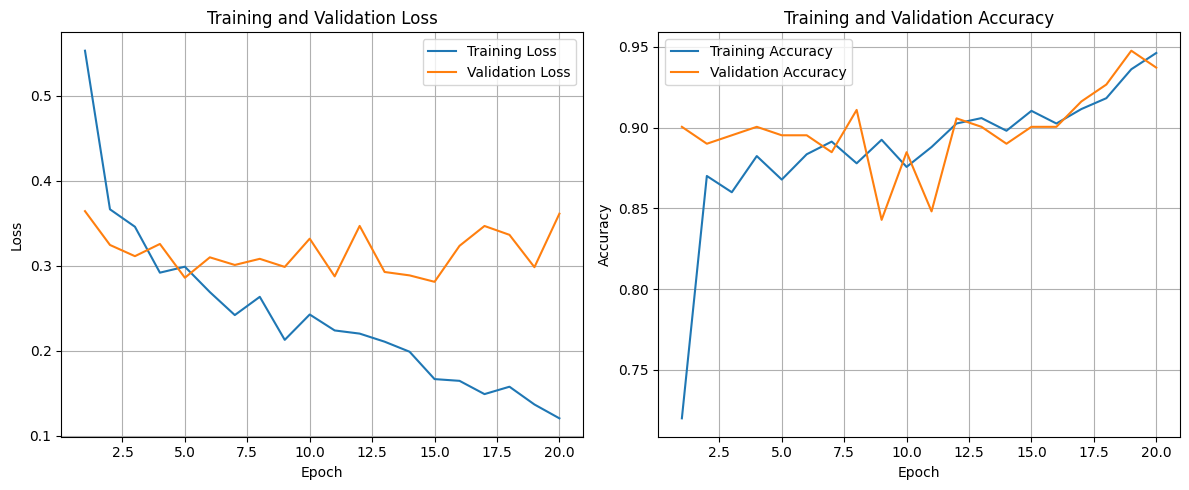

In [32]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label="Training Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Verify Training Results**

In [33]:
assert len(train_losses) == NUM_EPOCHS
assert len(val_losses) == NUM_EPOCHS
assert best_model_state is not None

print("Training completed successfully.")
print(f"Epochs completed: {len(train_losses)}")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Training accuracy at best epoch: {train_accuracies[best_epoch - 1]:.4f}")
print(f"Validation accuracy at best epoch: {val_accuracies[best_epoch - 1]:.4f}")

Training completed successfully.
Epochs completed: 20
Best epoch: 15
Best validation loss: 0.2810
Training accuracy at best epoch: 0.9104
Validation accuracy at best epoch: 0.9005


### Step 6: CNN Training and Validation

* Trained the CNN for 20 epochs using the training dataset.
* Evaluated the model on the validation dataset after each epoch.
* Recorded training and validation loss and accuracy for all epochs.
* Saved and restored the model weights from the epoch with the lowest validation loss.
* Achieved a best validation loss of **0.2810** at epoch 15, with a training accuracy of **91.04%** and a validation accuracy of **90.05%** at that epoch.
* Observed increasing training accuracy and decreasing training loss, with fluctuations in validation metrics that may indicate overfitting.
* Plotted training and validation curves to monitor model performance.

The CNN training stage is complete. The model is ready for final evaluation on the test dataset.


### 7. Final Model Evaluation

**Generate Test Predictions**

In [34]:
model.eval()

y_true = []
y_pred = []
y_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_probs.extend(probabilities[:, 1].cpu().numpy())

print(f"Test samples: {len(y_true)}")
print(f"Predictions generated: {len(y_pred)}")

Test samples: 192
Predictions generated: 192


**Calculate Evaluation Metrics**

In [35]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

class_names = ["non_emergency", "emergency"]

test_accuracy = accuracy_score(y_true, y_pred)
emergency_precision = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
emergency_recall = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
emergency_f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Emergency Precision: {emergency_precision:.4f}")
print(f"Emergency Recall: {emergency_recall:.4f}")
print(f"Emergency F1-score: {emergency_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=class_names,
        zero_division=0
    )
)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
print("Confusion Matrix:")
print(cm)

Test Accuracy: 0.9219
Emergency Precision: 0.7200
Emergency Recall: 0.9730
Emergency F1-score: 0.8276

Classification Report:
               precision    recall  f1-score   support

non_emergency       0.99      0.91      0.95       155
    emergency       0.72      0.97      0.83        37

     accuracy                           0.92       192
    macro avg       0.86      0.94      0.89       192
 weighted avg       0.94      0.92      0.93       192

Confusion Matrix:
[[141  14]
 [  1  36]]


**Visualize the Confusion Matrix**

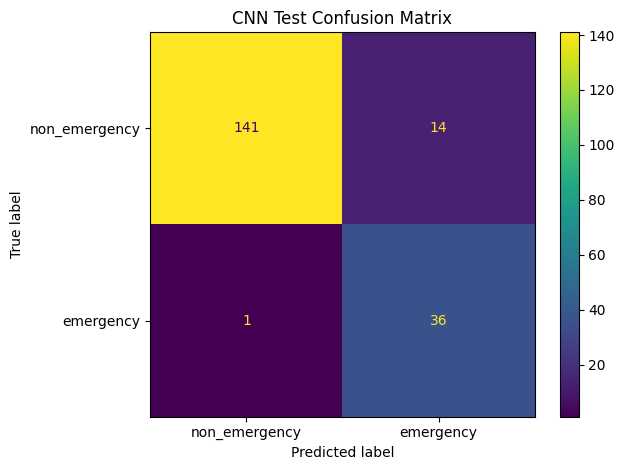

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(values_format="d")
plt.title("CNN Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [37]:
assert len(y_true) == len(test_dataset)
assert len(y_pred) == len(test_dataset)
assert len(y_probs) == len(test_dataset)
assert cm.shape == (2, 2)

print("Test evaluation completed successfully.")
print(f"Total test images: {len(test_dataset)}")
print(f"Correct predictions: {(cm[0, 0] + cm[1, 1])}")
print(f"Incorrect predictions: {(cm[0, 1] + cm[1, 0])}")
print(f"Emergency images missed: {cm[1, 0]}")

Test evaluation completed successfully.
Total test images: 192
Correct predictions: 177
Incorrect predictions: 15
Emergency images missed: 1


### Step 7: Final Model Evaluation

* Evaluated the trained CNN on 192 unseen test images.
* Achieved a test accuracy of **92.19%**.
* Obtained an emergency precision of **72.00%**, recall of **97.30%**, and F1-score of **82.76%**.
* Correctly classified 141 non-emergency images and 36 emergency images.
* Misclassified 14 non-emergency images as emergency and missed 1 emergency image.
* Used the classification report and confusion matrix to assess the model's performance on both classes.

The model achieved high emergency recall, although some non-emergency images were incorrectly classified as emergency.


### 8. Error Analysis


**Identify Misclassified Images**

In [38]:
import pandas as pd

test_results = test_df.reset_index(drop=True).copy()
test_results["true_label"] = [idx_to_class[label] for label in y_true]
test_results["predicted_label"] = [idx_to_class[label] for label in y_pred]
test_results["emergency_probability"] = y_probs
test_results["correct"] = test_results["true_label"] == test_results["predicted_label"]

misclassified_df = test_results[~test_results["correct"]].copy()

print(f"Total misclassified images: {len(misclassified_df)}")
print("\nMisclassification counts:")
print(
    misclassified_df.groupby(["true_label", "predicted_label"])
    .size()
    .reset_index(name="count")
)

Total misclassified images: 15

Misclassification counts:
      true_label predicted_label  count
0      emergency   non_emergency      1
1  non_emergency       emergency     14


**Display Missclassified Images**

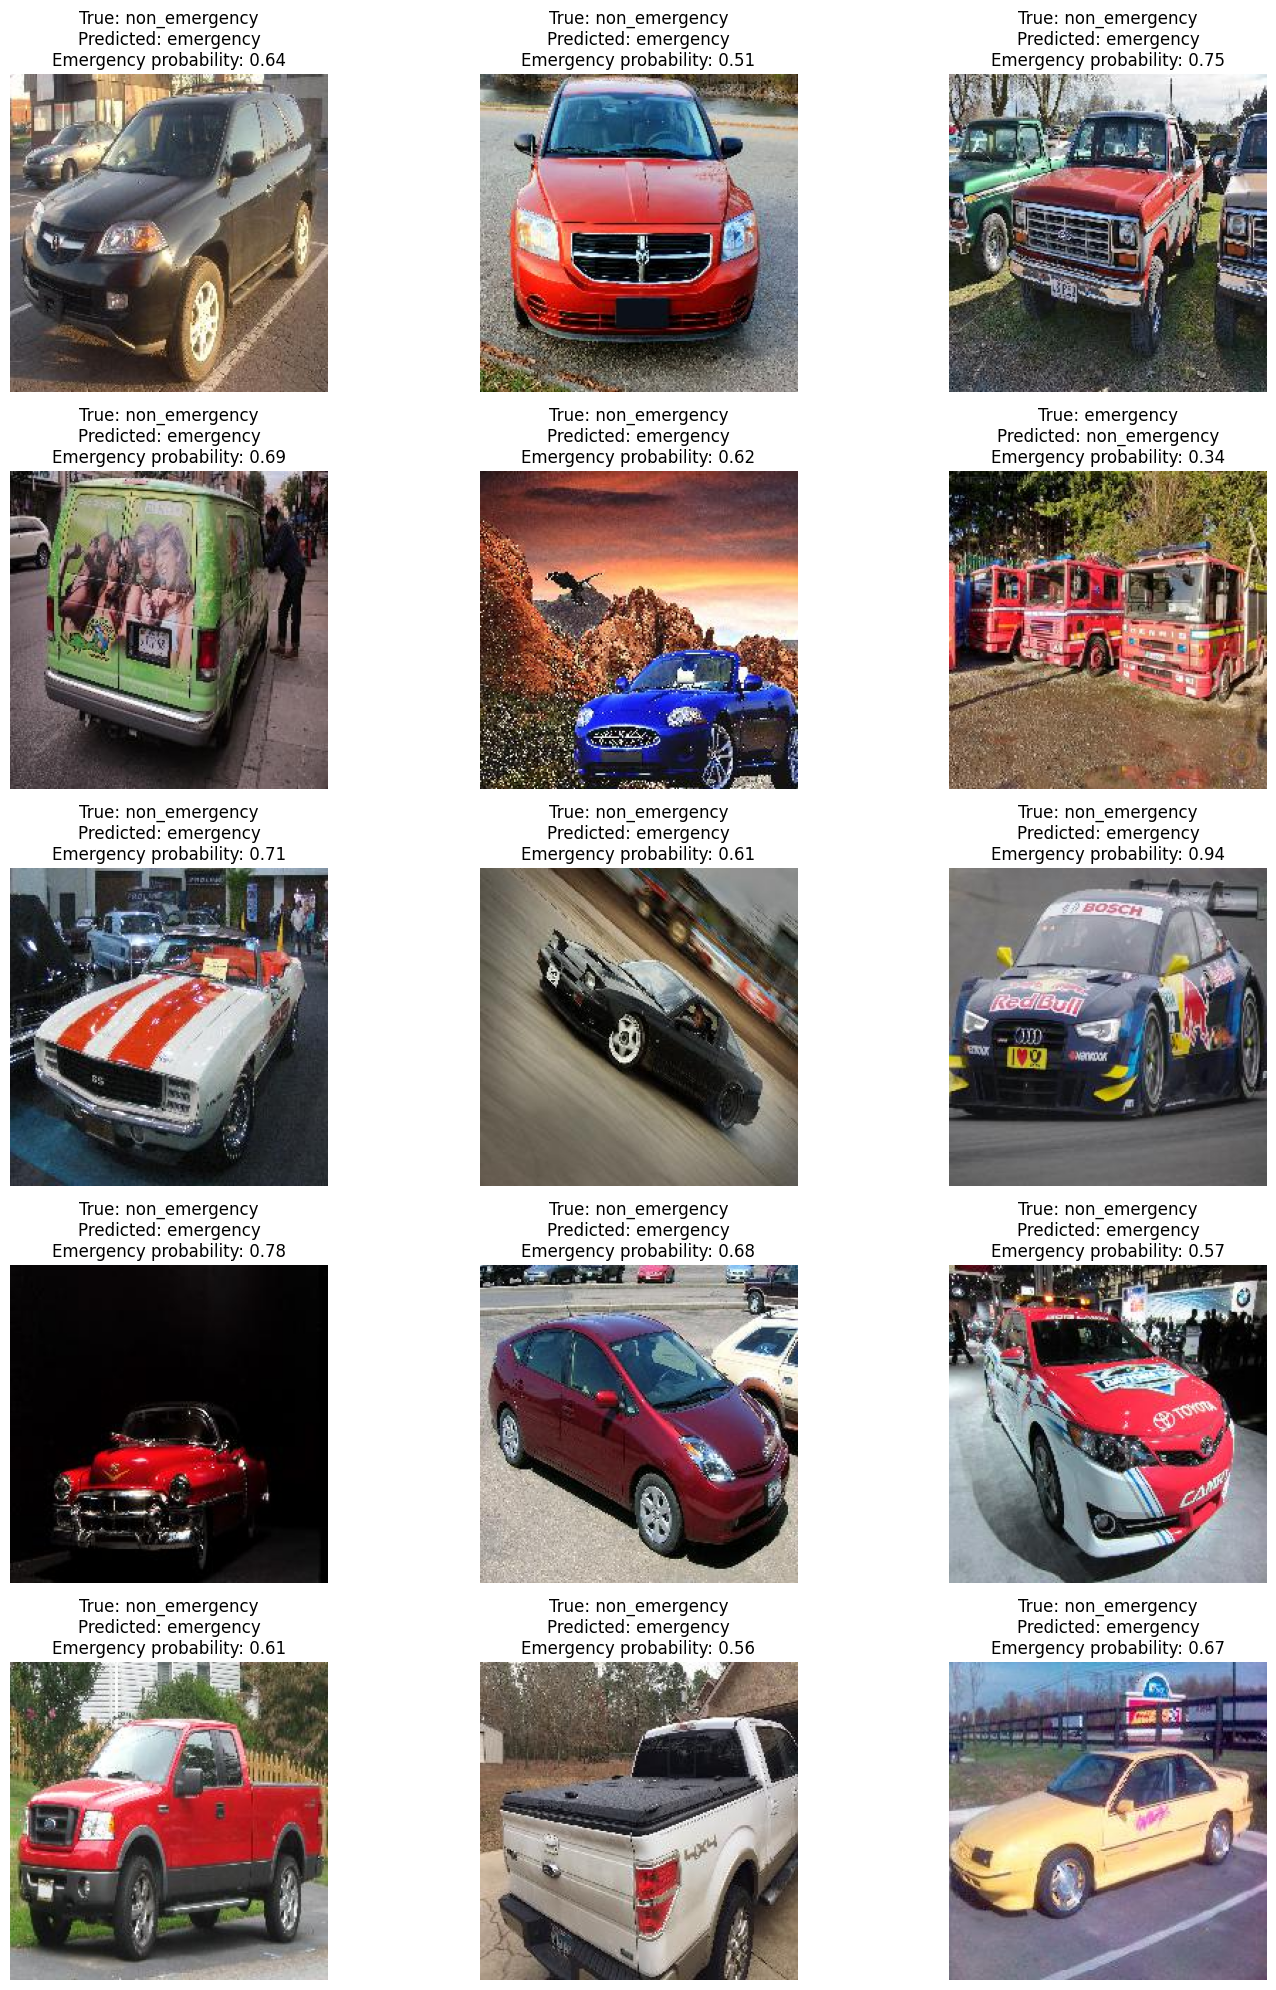

In [39]:
from PIL import Image
import matplotlib.pyplot as plt
import math

num_images = len(misclassified_df)
cols = 3
rows = math.ceil(num_images / cols)

plt.figure(figsize=(15, rows * 4))

for i, (_, row) in enumerate(misclassified_df.iterrows()):
    image = Image.open(row["path"]).convert("RGB")

    plt.subplot(rows, cols, i + 1)
    plt.imshow(image)
    plt.title(
        f"True: {row['true_label']}\n"
        f"Predicted: {row['predicted_label']}\n"
        f"Emergency probability: {row['emergency_probability']:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [40]:
false_positives = misclassified_df[
    (misclassified_df["true_label"] == "non_emergency") &
    (misclassified_df["predicted_label"] == "emergency")
]

false_negatives = misclassified_df[
    (misclassified_df["true_label"] == "emergency") &
    (misclassified_df["predicted_label"] == "non_emergency")
]

print(f"False positives: {len(false_positives)}")
print(f"False negatives: {len(false_negatives)}")

print("\nFalse positive image paths:")
for path in false_positives["path"]:
    print(path)

print("\nFalse negative image paths:")
for path in false_negatives["path"]:
    print(path)

False positives: 14
False negatives: 1

False positive image paths:
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\777a8e56-1825.jpg
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\961bd15b-1150.jpg
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\a5c66273-1016.jpg
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\00e495f6-1821.jpg
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\20769c6e-2198.jpg
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\5f077b6a-2031.jpg
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\21372985-1401.jpg
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\473dea67-2313.jpg
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\ca097128-994.jpg
C:\Users\Asus\Downloads\emergency_dataset_with_label\merged_dataset\images\5a212b71-1515.jpg
C:\

### 9. Save the Final Model and Results

In [41]:
from pathlib import Path

OUTPUT_DIR = Path("emergency_cnn_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "emergency_cnn.pth"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_to_idx": class_to_idx,
        "img_size": IMG_SIZE,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
    },
    model_path
)

print(f"Model saved to: {model_path.resolve()}")

Model saved to: C:\Program Files\Microsoft VS Code\emergency_cnn_results\emergency_cnn.pth


In [42]:
import json

metrics = {
    "test_samples": len(y_true),
    "test_accuracy": float(test_accuracy),
    "emergency_precision": float(emergency_precision),
    "emergency_recall": float(emergency_recall),
    "emergency_f1_score": float(emergency_f1),
    "correct_predictions": int((cm[0, 0] + cm[1, 1])),
    "incorrect_predictions": int((cm[0, 1] + cm[1, 0])),
    "false_positives": int(cm[0, 1]),
    "false_negatives": int(cm[1, 0]),
    "best_epoch": int(best_epoch),
    "best_validation_loss": float(best_val_loss),
}

metrics_path = OUTPUT_DIR / "evaluation_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print(f"Metrics saved to: {metrics_path.resolve()}")

Metrics saved to: C:\Program Files\Microsoft VS Code\emergency_cnn_results\evaluation_metrics.json


In [43]:
predictions_path = OUTPUT_DIR / "test_predictions.csv"

test_results.to_csv(predictions_path, index=False)

print(f"Test predictions saved to: {predictions_path.resolve()}")

Test predictions saved to: C:\Program Files\Microsoft VS Code\emergency_cnn_results\test_predictions.csv


In [44]:
required_files = [
    model_path,
    metrics_path,
    predictions_path
]

for file_path in required_files:
    assert file_path.exists(), f"Missing file: {file_path.name}"
    print(f"{file_path.name}: {file_path.stat().st_size:,} bytes")

print("All project results were saved successfully.")

emergency_cnn.pth: 1,427,557 bytes
evaluation_metrics.json: 380 bytes
test_predictions.csv: 31,239 bytes
All project results were saved successfully.


### TEST

In [45]:
random_samples = test_df.sample(n=6, random_state=42).reset_index(drop=True)

random_samples

,path,label,mixed,has_label_file
0,C:\Users\Asus\Downloads\emergency_dataset_with...,non_emergency,False,True
1,C:\Users\Asus\Downloads\emergency_dataset_with...,non_emergency,False,True
2,C:\Users\Asus\Downloads\emergency_dataset_with...,non_emergency,False,True
3,C:\Users\Asus\Downloads\emergency_dataset_with...,non_emergency,False,True
4,C:\Users\Asus\Downloads\emergency_dataset_with...,emergency,False,True
5,C:\Users\Asus\Downloads\emergency_dataset_with...,non_emergency,False,True


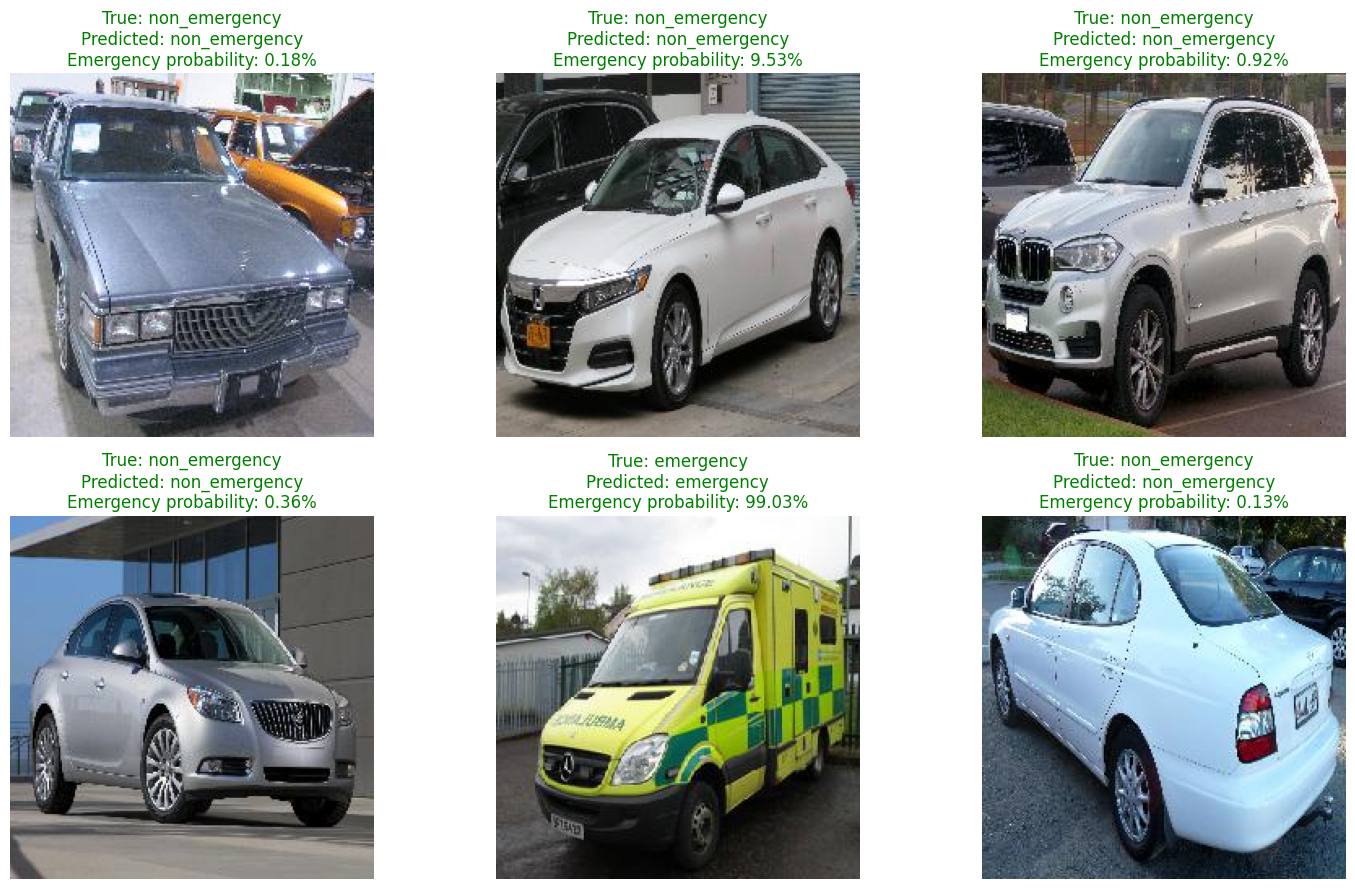

In [46]:
import matplotlib.pyplot as plt
from PIL import Image
import torch

model.eval()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, row in random_samples.iterrows():
    image = Image.open(row["path"]).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]
        predicted_idx = outputs.argmax(dim=1).item()

    predicted_label = idx_to_class[predicted_idx]
    true_label = row["label"]

    emergency_probability = probabilities[class_to_idx["emergency"]].item()

    axes[i].imshow(image)
    axes[i].set_title(
        f"True: {true_label}\n"
        f"Predicted: {predicted_label}\n"
        f"Emergency probability: {emergency_probability:.2%}",
        color="green" if predicted_label == true_label else "red"
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [47]:
random_test_results = []

model.eval()

for _, row in random_samples.iterrows():
    image = Image.open(row["path"]).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]
        predicted_idx = outputs.argmax(dim=1).item()

    random_test_results.append({
        "image": Path(row["path"]).name,
        "true_label": row["label"],
        "predicted_label": idx_to_class[predicted_idx],
        "emergency_probability": round(
            probabilities[class_to_idx["emergency"]].item(), 4
        ),
        "correct": idx_to_class[predicted_idx] == row["label"]
    })

random_test_df = pd.DataFrame(random_test_results)
random_test_df

,image,true_label,predicted_label,emergency_probability,correct
0,904888b8-1092.jpg,non_emergency,non_emergency,0.0018,True
1,aa9b28b6-1492.jpg,non_emergency,non_emergency,0.0953,True
2,313dc201-2054.jpg,non_emergency,non_emergency,0.0092,True
3,dac31c1a-1572.jpg,non_emergency,non_emergency,0.0036,True
4,456b24ed-741.jpg,emergency,emergency,0.9903,True
5,3e4ef14d-1124.jpg,non_emergency,non_emergency,0.0013,True
